# Introduction - Query Model

In [1]:
import pennylane as qp
import pennylane.numpy as np
from utils import plot_hist

# Hadamard Transform

1) Definition:
$$H^{\otimes n}|x\rangle = \frac{1}{\sqrt{2^n}} \sum_{y \in \{0,1\}^n} (-1)^{x \cdot y}\, |y\rangle$$

2) Applied to the zero state: what can you say about the output state?

$$H^{\otimes n}|0\cdots0\rangle = \frac{1}{\sqrt{2^n}} \sum_{y \in \{0,1\}^n} |y\rangle$$

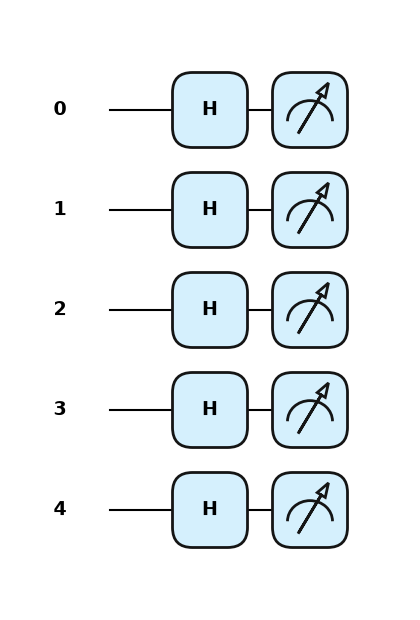

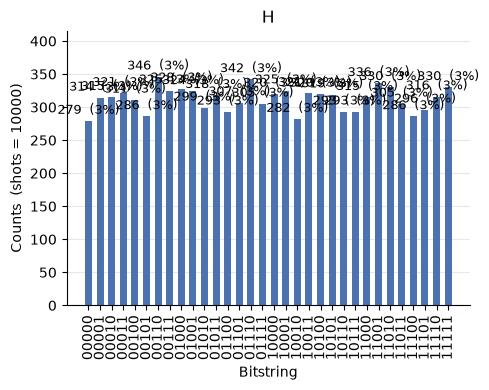

In [6]:
n_bits=5

dev = qp.device("default.qubit", wires=n_bits)

@qp.set_shots(shots=10000)
@qp.qnode(dev)
def had():
    for q in range(n_bits):
        qp.Hadamard(wires=q)
    return qp.counts()

counts=had()
qp.draw_mpl(had,style="pennylane")()
plot_hist(counts,title="H")

In [7]:
@qp.qnode(dev)
def had():
    for q in range(n_bits):
        qp.Hadamard(wires=q)
    return qp.state()

had()

array([0.1767767+0.j, 0.1767767+0.j, 0.1767767+0.j, 0.1767767+0.j,
       0.1767767+0.j, 0.1767767+0.j, 0.1767767+0.j, 0.1767767+0.j,
       0.1767767+0.j, 0.1767767+0.j, 0.1767767+0.j, 0.1767767+0.j,
       0.1767767+0.j, 0.1767767+0.j, 0.1767767+0.j, 0.1767767+0.j,
       0.1767767+0.j, 0.1767767+0.j, 0.1767767+0.j, 0.1767767+0.j,
       0.1767767+0.j, 0.1767767+0.j, 0.1767767+0.j, 0.1767767+0.j,
       0.1767767+0.j, 0.1767767+0.j, 0.1767767+0.j, 0.1767767+0.j,
       0.1767767+0.j, 0.1767767+0.j, 0.1767767+0.j, 0.1767767+0.j])

# Deutsch's algorithm

Let's implemlement the following oracle given Figure 1 from the Seminar Handout:

$U_f \ket{x}\ket{y}=\ket{x}\ket{y\oplus f(x)}$

In [8]:

dev = qp.device("default.qubit", wires=2)

def oracle(f):
    if f == "const_0":
        pass
    elif f == "const_1":
        qp.PauliX(wires=1)
    elif f == "identity":        
        qp.CNOT(wires=[0,1])
    elif f == "negation":        
        qp.PauliX(wires=1)
        qp.CNOT(wires=[0,1])

Here is the circuit:

![Deutsch circuit](figures/deutsch.png)

In [9]:

@qp.qnode(dev)
def deutsch(f):
    qp.Hadamard(wires=0)
    qp.PauliX(wires=1)
    qp.Hadamard(wires=1)
    oracle(f)
    qp.Hadamard(wires=0)
    return qp.probs(wires=0)

for f in ["const_0", "const_1", "identity", "negation"]:
    p = deutsch(f)
    print(f"{f:9s} P(0)={p[0]:.2f}  ->", "constant" if p[0] > 0.5 else "balanced")

const_0   P(0)=1.00  -> constant
const_1   P(0)=1.00  -> constant
identity  P(0)=0.00  -> balanced
negation  P(0)=0.00  -> balanced


(<Figure size 800x300 with 1 Axes>, <Axes: >)

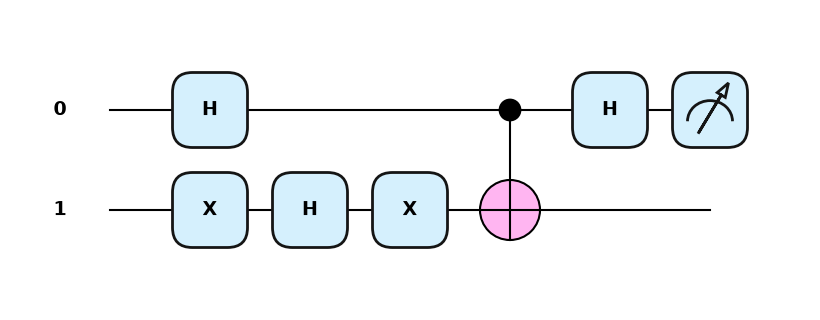

In [10]:
qp.draw_mpl(deutsch,style = "pennylane")("negation")

# Deutsch-Jozsa algorithm

Here is the circuit:

![Deutsch circuit](figures/dj.png)

In [11]:
n_bits = 4
dev = qp.device("default.qubit", wires=n_bits)

We have a boolean function  $f:\{0,1\}^n\rightarrow\{0,1\}$ s.t.:
$$f(x) = 1 \iff x \in \texttt{combos}$$

We can also call $\texttt{combos}$ as $S = \{x : f(x) = 1\}$

In [12]:
def multisol_combo(n_bits, how_many):
    """Return how_many distinct random bit strings of length n_bits."""
    indices = np.random.choice(2**n_bits, size=how_many, replace=False)
    return [[int(b) for b in np.binary_repr(i, width=n_bits)] for i in indices]

In [15]:
multisol_combo(n_bits, 3)

[[1, 0, 0, 0], [0, 0, 0, 0], [0, 1, 0, 0]]

### Let's create the oracle

$$U_f = I - 2\sum_{s\in S}|s\rangle\langle s|, \qquad U_f|x\rangle = (-1)^{f(x)}|x\rangle,$$
where $S = \{x : f(x) = 1\}$.

Here we build a phase oracle rather than a bit oracle as we did for Deutsch's algorithm. If the extra qubit starts in $|-\rangle = H|1\rangle$, flipping it multiplies the state by $-1$, so the bit oracle $|x\rangle|y\rangle \to |x\rangle|y \oplus f(x)\rangle$ acts as the phase oracle $|x\rangle \to (-1)^{f(x)}|x\rangle$. So the two types of oracle do the same thing; they're just implemented differently.

The circuit will look like:



![Deutsch circuit](figures/dj_phase.png)

In [16]:
def multisol_oracle_matrix(combos):
    """
    Args:
        combos (list[list[int]]): A list of secret bit strings.

    Returns:
        array[float]: The matrix representation of the oracle.
    """
    # Create the identity matrix
    matrix = np.identity(2**n_bits)

    # convert each bit string in combos into its integer index, i.e. its position in the state vector or matrix.
    # hint: use "np.ravel_multi_index"
    idx=[np.ravel_multi_index(c, [2]*n_bits) for c in combos]

    # Apply the indices
    for i in idx:
        matrix[i,i]=-1
    
    return matrix

In [17]:
#Just a check:
n_bits = 3
combos=multisol_combo(n_bits, 2)
print(combos)
multisol_oracle_matrix(combos)

[[0, 0, 0], [1, 0, 0]]


tensor([[-1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.],
        [ 0.,  1.,  0.,  0.,  0.,  0.,  0.,  0.],
        [ 0.,  0.,  1.,  0.,  0.,  0.,  0.,  0.],
        [ 0.,  0.,  0.,  1.,  0.,  0.,  0.,  0.],
        [ 0.,  0.,  0.,  0., -1.,  0.,  0.,  0.],
        [ 0.,  0.,  0.,  0.,  0.,  1.,  0.,  0.],
        [ 0.,  0.,  0.,  0.,  0.,  0.,  1.,  0.],
        [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.]], requires_grad=True)

Let's do the DJ circuit using pennylane's function ` qp.QubitUnitary(matrix, wires=range(n_bits))`. It allows to create a gate out of the matrix we've just built!

In [18]:
n_bits = 4


@qp.qnode(dev)
def circuit(combos):
    """
    Args:
        combos (list[list[int]]): A list of secret bit strings.

    Returns: 
        array[float]: Probabilities for observing different outcomes.
    """
    #Do the Hadamard Transform
    for q in range(n_bits):
        qp.Hadamard(wires=q)

    # Apply the oracle we built
    qp.QubitUnitary(multisol_oracle_matrix(combos), wires=range(n_bits))

    #Redo the Hadamard Transform
    for q in range(n_bits):
        qp.Hadamard(wires=q)

    # Return the probabilies
    return qp.probs(wires=range(n_bits))

In [20]:
def deutsch_jozsa(promise_var):
    """Implements the Deutsch–Jozsa algorithm and guesses the promise variable.
    
    Args:
        promise_var (int): Indicates whether the function is balanced (0) or constant (1).
        
    Returns: 
        int: A guess at the promise variable.
    """
    if promise_var == 0:
        how_many = 2**(n_bits - 1)
    else:
        how_many = np.random.choice([0, 2**n_bits]) 

    combos = multisol_combo(n_bits, how_many) # Generate random combinations
    zero_prob = circuit(combos)[0] # Probability of observing the all-zero state
    guess = int(np.rint(zero_prob)) # Round to nearest integer
    return guess

In [22]:
deutsch_jozsa(0)

0

(<Figure size 600x500 with 1 Axes>, <Axes: >)

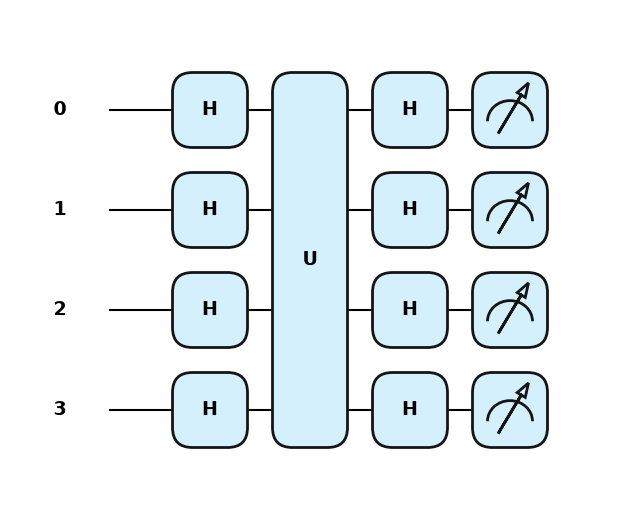

In [23]:
how_many = 2**(n_bits - 1)
combos = multisol_combo(n_bits, how_many) # Generate random combinations
qp.draw_mpl(circuit,style = "pennylane")(combos)

In [24]:
import itertools

n_bits = 3
dev = qp.device("default.qubit", wires=n_bits)

def oracle_from_function(f):
    """Phase oracle U_f |x> = (-1)^f(x) |x>."""
    inputs = itertools.product([0, 1], repeat=n_bits)  # |00..0>, |00..1>, ... in basis order
    return np.diag([(-1) ** f(x) for x in inputs])

@qp.qnode(dev)
def hoh_circuit(U):
    for q in range(n_bits):
        qp.Hadamard(wires=q)

    qp.QubitUnitary(U,wires=range(n_bits))

    for q in range(n_bits):
        qp.Hadamard(wires=q)
    return qp.probs(wires=range(n_bits))

def deutsch_jozsa(f):
    zero_prob = hoh_circuit(oracle_from_function(f))[0]
    return "constant" if np.isclose(zero_prob, 1) else "balanced"

# Examples
print(deutsch_jozsa(lambda x: 0))             # constant
print(deutsch_jozsa(lambda x: 1))             # constant
print(deutsch_jozsa(lambda x: x[0]))          # balanced
print(deutsch_jozsa(lambda x: sum(x) % 2))    # balanced

constant
constant
balanced
balanced


# Simon's Algorithm

**Problem.** We are given $f:\{0,1\}^n \to \{0,1\}^n$ with the promise that there is a secret $s \neq 0\cdots0$ such that
$$f(x) = f(y) \iff y = x \text{ or } y = x \oplus s.$$
So $f$ is periodic with period $s$ (under XOR): inputs come in pairs $\{x, x \oplus s\}$ that share an output, and different pairs have different outputs. The goal is to find $s$.



Let's consider a 2-qubit example ($n = 2$). Wires $0, 1$ hold the input $x$, and wires $2, 3$ start in $|00\rangle$ and receive the output:
$$|x\rangle|00\rangle \to |x\rangle|f(x)\rangle$$

Oracle:
1) Copy $x$ onto the output wires: a CNOT from each input wire $i$ to output wire $n+i$.
2) Pick a position $j$ where $s$ has a 1, then add a CNOT from wire $j$ to each output wire $n+i$ where $s_i = 1$.

If $x_j = 0$, none of these CNOTs fire, so the output stays $x$.
If $x_j = 1$, they all fire. Each 1 in $s$ flips the corresponding output bit, so the output becomes $x \oplus s$.

In [25]:
n_bits = 4
dev = qp.device("default.qubit", wires=n_bits)

In [26]:
def simons_oracle(s):
    n = len(s)
    for i in range(n):
        qp.CNOT(wires=[i, n + i])
    for j in range(n):
        if s[j] == 1:
            break    
    for i in range(n):
        if s[i] == 1:
            qp.CNOT(wires=[j, n + i])

In [35]:
@qp.set_shots(shots=10)
@qp.qnode(dev)
def simons(s):
    n=len(s)
    for q in range(n):
        qp.Hadamard(wires=q)
    simons_oracle(s)
    for q in range(n):
        qp.Hadamard(wires=q)
    return qp.probs(wires=range(n))

what happens for s=11?

In [36]:

probs = simons([1,1])

# outcomes we actually observe (nonzero probability)
ys = [format(i, "02b") for i in range(4) if probs[i] > 1e-9]

(<Figure size 900x500 with 1 Axes>, <Axes: >)

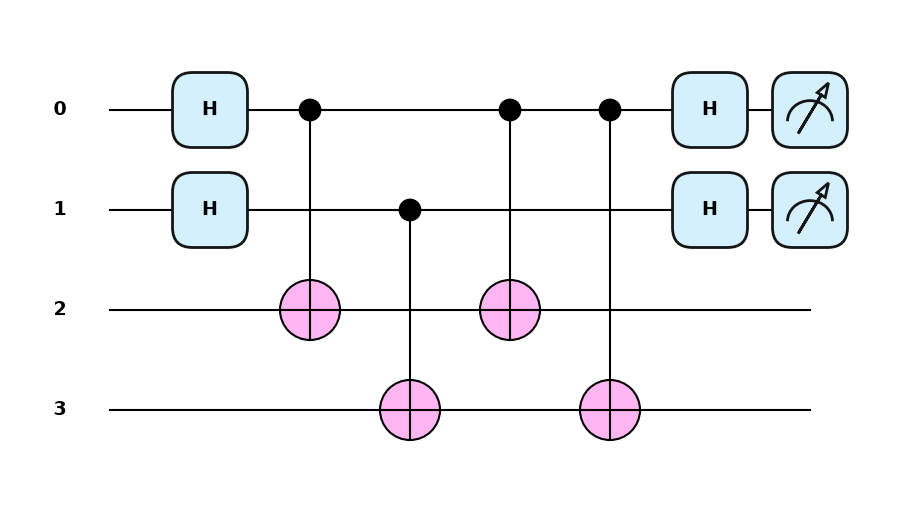

In [37]:
qp.draw_mpl(simons,style = "pennylane")([1,1])

In [38]:
for s in ["01", "10", "11"]:          # why s=00 excluded?
    if all(sum(int(a) * int(b) for a, b in zip(y, s)) % 2 == 0 for y in ys):
        print("s =", s)               

s = 11


# Outlook: from matrices to gates

We built the oracles as matrices and applied them with `qp.QubitUnitary`. Real hardware only has a small set of instructions: how do we turn an arbitrary unitary into such gates, and at what cost? That's **compiling**, we'll talk about it in 2 weeks. Next week we will explore a very known algorithm: Grover's algorithm